# Mini-Project 1
## Advanced Python Data Exploration & Visulaizations

# 1. Import libraries

In [2]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# 2. Load the data using Try & Except

In [3]:
def load_sales_data(file_path):
    try:
        data = pd.read_excel(file_path, sheet_name="Sales Data", usecols="A:X")
        print("File loaded successfully")
        return data
    except FileNotFoundError:
        print("File not found")

In [5]:
FILE_PATH = r'C:\Users\eslam\Downloads\DEPI\Technical\Sales Data.xlsx'

data = load_sales_data(FILE_PATH)

File loaded successfully


# 2. Inspect the dataset

In [6]:
# List all column names
data.columns

Index(['Order ID', 'Year', 'Month', 'Order Date', 'Ship Date', 'Ship Mode',
       'Customer ID', 'Customer Name', 'Client Segment', 'Country', 'State',
       'Postal Code', 'Region', 'Product ID', 'Product Category',
       'Sub-Category', 'Product Name', 'Sales Price', 'Quantity', 'Discount',
       'Total Sales Amount', 'Purchasing Price', 'Total Purchasing Amounts',
       'Net Profit'],
      dtype='str')

In [7]:
# Display summary of DataFrame
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 1008 entries, 0 to 1007
Data columns (total 24 columns):
 #   Column                    Non-Null Count  Dtype         
---  ------                    --------------  -----         
 0   Order ID                  1007 non-null   str           
 1   Year                      1007 non-null   float64       
 2   Month                     1007 non-null   str           
 3   Order Date                1007 non-null   datetime64[us]
 4   Ship Date                 1007 non-null   datetime64[us]
 5   Ship Mode                 1007 non-null   str           
 6   Customer ID               1007 non-null   str           
 7   Customer Name             1007 non-null   str           
 8   Client Segment            1007 non-null   str           
 9   Country                   1007 non-null   str           
 10  State                     1007 non-null   str           
 11  Postal Code               1007 non-null   float64       
 12  Region                    1007 

In [8]:
# Descriptive statistics
print(data.describe(include='all'))

              Order ID         Year Month                  Order Date  \
count             1007  1007.000000  1007                        1007   
unique             488          NaN    12                         NaN   
top     CA-2017-117457          NaN   Dec                         NaN   
freq                 9          NaN   153                         NaN   
mean               NaN  2015.785501   NaN  2016-04-04 17:13:52.969215   
min                NaN  2014.000000   NaN         2014-01-04 00:00:00   
25%                NaN  2015.000000   NaN         2015-04-26 00:00:00   
50%                NaN  2016.000000   NaN         2016-05-30 00:00:00   
75%                NaN  2017.000000   NaN         2017-04-07 00:00:00   
max                NaN  2020.000000   NaN         2017-12-30 00:00:00   
std                NaN     1.289069   NaN                         NaN   

                         Ship Date       Ship Mode Customer ID  \
count                         1007            1007       

In [9]:
# Preview first 5 rows
display(data.head())

,Order ID,Year,Month,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Client Segment,Country,...,Product Category,Sub-Category,Product Name,Sales Price,Quantity,Discount,Total Sales Amount,Purchasing Price,Total Purchasing Amounts,Net Profit
0,CA-2016-152156,2020.0,Nov,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,...,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2.0,0.0,523.9200,157.17600,314.35200,209.56800
1,CA-2016-152156,2020.0,Nov,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,...,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3.0,0.0,2195.8200,402.56700,1207.70100,988.11900
2,CA-2016-138688,2020.0,Jun,2016-06-12,2016-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,...,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2.0,0.0,29.2400,8.77200,17.54400,11.69600
3,US-2015-108966,2020.0,Oct,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,...,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5.0,0.0,4787.8875,478.78875,2393.94375,2393.94375
4,US-2015-108966,2020.0,Oct,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,...,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2.0,0.0,35.7888,11.18400,22.36800,13.42080


In [10]:
# Missing values
print(data.isnull().sum())

# Rows containing missing values
display(data[data.isnull().any(axis=1)])

Order ID                    1
Year                        1
Month                       1
Order Date                  1
Ship Date                   1
Ship Mode                   1
Customer ID                 1
Customer Name               1
Client Segment              1
Country                     1
State                       1
Postal Code                 1
Region                      1
Product ID                  1
Product Category            1
Sub-Category                1
Product Name                1
Sales Price                 1
Quantity                    1
Discount                    1
Total Sales Amount          1
Purchasing Price            1
Total Purchasing Amounts    1
Net Profit                  1
dtype: int64


,Order ID,Year,Month,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Client Segment,Country,...,Product Category,Sub-Category,Product Name,Sales Price,Quantity,Discount,Total Sales Amount,Purchasing Price,Total Purchasing Amounts,Net Profit
1007,NaN,NaN,NaN,NaT,NaT,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


# 3. Basic cleaning

In [11]:
# Remove completely empty rows
data.dropna(how='all', inplace=True)

## Data Type handling

In [12]:
# Check data types
print(data.dtypes)

Order ID                               str
Year                               float64
Month                                  str
Order Date                  datetime64[us]
Ship Date                   datetime64[us]
Ship Mode                              str
Customer ID                            str
Customer Name                          str
Client Segment                         str
Country                                str
State                                  str
Postal Code                        float64
Region                                 str
Product ID                             str
Product Category                       str
Sub-Category                           str
Product Name                           str
Sales Price                        float64
Quantity                           float64
Discount                           float64
Total Sales Amount                 float64
Purchasing Price                   float64
Total Purchasing Amounts           float64
Net Profit 

In [13]:
# Convert data types
data['Year'] = data['Year'].astype('int')
data['Quantity'] = data['Quantity'].astype('int')
data['Postal Code'] = data['Postal Code'].astype(str)

# Convert dates
data['Order Date'] = pd.to_datetime(data['Order Date'])
data['Ship Date'] = pd.to_datetime(data['Ship Date'])

print(data[['Year', 'Quantity', 'Postal Code']].dtypes)

Year           int64
Quantity       int64
Postal Code      str
dtype: object


# 4. Check and remove duplicates

In [14]:
print("Duplicate rows:", data.duplicated().sum())

display(data[data.duplicated(keep=False)])

data = data.drop_duplicates()

print("Duplicate rows after cleaning:", data.duplicated().sum())

Duplicate rows: 0


,Order ID,Year,Month,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Client Segment,Country,...,Product Category,Sub-Category,Product Name,Sales Price,Quantity,Discount,Total Sales Amount,Purchasing Price,Total Purchasing Amounts,Net Profit


Duplicate rows after cleaning: 0


# 5. Check and fill missing values

In [15]:
def check_missing(data):
    print(data.isna().sum())

def fill_missing(data):

    numeric_cols = data.select_dtypes(include="number").columns
    data[numeric_cols] = data[numeric_cols].fillna(data[numeric_cols].median())

    text_cols = data.select_dtypes(include=["string", "category"]).columns

    data[text_cols] = data[text_cols].fillna("Unknown")

    return data

In [16]:
check_missing(data)
data = fill_missing(data)

print("Missing values after cleaning:")
print(data.isna().sum())


Order ID                    0
Year                        0
Month                       0
Order Date                  0
Ship Date                   0
Ship Mode                   0
Customer ID                 0
Customer Name               0
Client Segment              0
Country                     0
State                       0
Postal Code                 0
Region                      0
Product ID                  0
Product Category            0
Sub-Category                0
Product Name                0
Sales Price                 0
Quantity                    0
Discount                    0
Total Sales Amount          0
Purchasing Price            0
Total Purchasing Amounts    0
Net Profit                  0
dtype: int64
Missing values after cleaning:
Order ID                    0
Year                        0
Month                       0
Order Date                  0
Ship Date                   0
Ship Mode                   0
Customer ID                 0
Customer Name             

# 6. Check inconsistent Year values

In [17]:
data['Order_Year'] = data['Order Date'].dt.year
data['Year_Inconsistent'] = data['Year'] != data['Order_Year']

print("Inconsistent Year rows:", data['Year_Inconsistent'].sum())

# Use Order Date year for analysis
data['Year'] = data['Order_Year']

display(data[data['Year_Inconsistent']][['Order ID', 'Year', 'Order_Year', 'Order Date']].head(10))


Inconsistent Year rows: 26


,Order ID,Year,Order_Year,Order Date
0,CA-2016-152156,2016,2016,2016-11-08
1,CA-2016-152156,2016,2016,2016-11-08
2,CA-2016-138688,2016,2016,2016-06-12
3,US-2015-108966,2015,2015,2015-10-11
4,US-2015-108966,2015,2015,2015-10-11
5,CA-2014-115812,2014,2014,2014-06-09
6,CA-2014-115812,2014,2014,2014-06-09
7,CA-2014-115812,2014,2014,2014-06-09
8,CA-2014-115812,2014,2014,2014-06-09
9,CA-2014-115812,2014,2014,2014-06-09


# 7. Outlier detection

In [18]:
def find_outliers(data, column):
    q1 = data[column].quantile(0.25)
    q3 = data[column].quantile(0.75)
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    outliers = data[
        (data[column] < lower) |
        (data[column] > upper)
    ]

    return outliers

In [19]:
sales_outliers = find_outliers(data, 'Total Sales Amount')
profit_outliers = find_outliers(data, 'Net Profit')

print("Sales outliers:")
display(sales_outliers)

print("Profit outliers:")
display(profit_outliers)


Sales outliers:


,Order ID,Year,Month,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Client Segment,Country,...,Product Name,Sales Price,Quantity,Discount,Total Sales Amount,Purchasing Price,Total Purchasing Amounts,Net Profit,Order_Year,Year_Inconsistent
1,CA-2016-152156,2016,Nov,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,...,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.0,2195.8200,402.56700,1207.70100,988.11900,2016,True
3,US-2015-108966,2015,Oct,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,...,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.0,4787.8875,478.78875,2393.94375,2393.94375,2015,True
7,CA-2014-115812,2014,Jun,2014-06-09,2014-06-14,Standard Class,BH-11710,Brosina Hoffman,Consumer,United States,...,Mitel 5320 IP Phone VoIP phone,907.1520,6,0.0,4354.3296,635.00640,3810.03840,544.29120,2014,True
10,CA-2014-115812,2014,Jun,2014-06-09,2014-06-14,Standard Class,BH-11710,Brosina Hoffman,Consumer,United States,...,Chromcraft Rectangular Conference Tables,1706.1840,9,0.0,12284.5248,1023.71040,9213.39360,3071.13120,2014,True
11,CA-2014-115812,2014,Jun,2014-06-09,2014-06-14,Standard Class,BH-11710,Brosina Hoffman,Consumer,United States,...,Konftel 250 Conference phone - Charcoal black,911.4240,4,0.0,2916.5568,501.28320,2005.13280,911.42400,2014,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
982,CA-2014-117639,2014,May,2014-05-21,2014-05-25,Standard Class,MW-18235,Mitch Willingham,Corporate,United States,...,Fellowes PB300 Plastic Comb Binding Machine,2715.9300,7,0.0,19011.5100,1357.96500,9505.75500,9505.75500,2014,False
983,CA-2014-117639,2014,May,2014-05-21,2014-05-25,Standard Class,MW-18235,Mitch Willingham,Corporate,United States,...,Plantronics Voyager Pro Legend,617.9700,3,0.0,1853.9100,401.68050,1205.04150,648.86850,2014,False
989,CA-2015-124891,2015,Jul,2015-07-31,2015-07-31,Same Day,RH-19495,Rick Hansen,Consumer,United States,...,Plantronics CS510 - Over-the-Head monaural Wir...,2309.6500,7,0.0,16167.5500,1270.30750,8892.15250,7275.39750,2015,False
990,CA-2015-124891,2015,Jul,2015-07-31,2015-07-31,Same Day,RH-19495,Rick Hansen,Consumer,United States,...,"Bevis Round Bullnose 29"" High Table Top",1090.7820,7,0.0,7635.4740,654.46920,4581.28440,3054.18960,2015,False


Profit outliers:


,Order ID,Year,Month,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Client Segment,Country,...,Product Name,Sales Price,Quantity,Discount,Total Sales Amount,Purchasing Price,Total Purchasing Amounts,Net Profit,Order_Year,Year_Inconsistent
1,CA-2016-152156,2016,Nov,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,...,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.0,2195.8200,402.56700,1207.70100,988.11900,2016,True
3,US-2015-108966,2015,Oct,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,...,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.0,4787.8875,478.78875,2393.94375,2393.94375,2015,True
10,CA-2014-115812,2014,Jun,2014-06-09,2014-06-14,Standard Class,BH-11710,Brosina Hoffman,Consumer,United States,...,Chromcraft Rectangular Conference Tables,1706.1840,9,0.0,12284.5248,1023.71040,9213.39360,3071.13120,2014,True
11,CA-2014-115812,2014,Jun,2014-06-09,2014-06-14,Standard Class,BH-11710,Brosina Hoffman,Consumer,United States,...,Konftel 250 Conference phone - Charcoal black,911.4240,4,0.0,2916.5568,501.28320,2005.13280,911.42400,2014,True
16,CA-2014-105893,2014,Nov,2014-11-11,2014-11-18,Standard Class,PK-19075,Pete Kriz,Consumer,United States,...,"Stur-D-Stor Shelving, Vertical 5-Shelf: 72""H x...",665.8800,6,0.0,3995.2800,399.52800,2397.16800,1598.11200,2014,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
983,CA-2014-117639,2014,May,2014-05-21,2014-05-25,Standard Class,MW-18235,Mitch Willingham,Corporate,United States,...,Plantronics Voyager Pro Legend,617.9700,3,0.0,1853.9100,401.68050,1205.04150,648.86850,2014,False
989,CA-2015-124891,2015,Jul,2015-07-31,2015-07-31,Same Day,RH-19495,Rick Hansen,Consumer,United States,...,Plantronics CS510 - Over-the-Head monaural Wir...,2309.6500,7,0.0,16167.5500,1270.30750,8892.15250,7275.39750,2015,False
990,CA-2015-124891,2015,Jul,2015-07-31,2015-07-31,Same Day,RH-19495,Rick Hansen,Consumer,United States,...,"Bevis Round Bullnose 29"" High Table Top",1090.7820,7,0.0,7635.4740,654.46920,4581.28440,3054.18960,2015,False
992,CA-2015-126445,2015,Aug,2015-08-27,2015-08-31,Standard Class,RA-19945,Ryan Akin,Consumer,United States,...,Fellowes Super Stor/Drawer Files,484.6500,3,0.0,1453.9500,242.32500,726.97500,726.97500,2015,False


# 8. Feature engineering

In [20]:
def engineer_features(data):

    # Profit Margin
    data["Profit_Margin"] = (
        data["Net Profit"] / data["Total Sales Amount"]
    )

    # Shipping Duration
    data["Shipping_Duration_Days"] = (
        data["Ship Date"] - data["Order Date"]
    ).dt.days

    # Sales Performance Category
    q1 = data["Total Sales Amount"].quantile(0.25)
    q3 = data["Total Sales Amount"].quantile(0.75)

    data["Sales_Performance_Category"] = "Medium"

    data.loc[
        data["Total Sales Amount"] < q1,
        "Sales_Performance_Category"
    ] = "Low"

    data.loc[
        data["Total Sales Amount"] > q3,
        "Sales_Performance_Category"
    ] = "High"

    return data

In [21]:
data = engineer_features(data)

display(data[[
    'Order Date', 'Ship Date', 'Total Sales Amount', 'Net Profit',
    'Profit_Margin', 'Shipping_Duration_Days',
    'Sales_Performance_Category'
]].head(10))

,Order Date,Ship Date,Total Sales Amount,Net Profit,Profit_Margin,Shipping_Duration_Days,Sales_Performance_Category
0,2016-11-08,2016-11-11,523.9200,209.56800,0.400,3,Medium
1,2016-11-08,2016-11-11,2195.8200,988.11900,0.450,3,High
2,2016-06-12,2016-06-16,29.2400,11.69600,0.400,4,Low
3,2015-10-11,2015-10-18,4787.8875,2393.94375,0.500,7,High
4,2015-10-11,2015-10-18,35.7888,13.42080,0.375,7,Low
5,2014-06-09,2014-06-14,342.0200,119.70700,0.350,5,Medium
6,2014-06-09,2014-06-14,29.1200,11.64800,0.400,5,Low
7,2014-06-09,2014-06-14,4354.3296,544.29120,0.125,5,High
8,2014-06-09,2014-06-14,44.4096,5.55120,0.125,5,Low
9,2014-06-09,2014-06-14,574.5000,201.07500,0.350,5,Medium


# 9. Memory optimization

In [22]:
def optimize_memory(data):

    for col in data.select_dtypes(include='int64'):
        data[col] = pd.to_numeric(data[col], downcast='integer')

    for col in data.select_dtypes(include='float64'):
        data[col] = pd.to_numeric(data[col], downcast='float')

    for col in data.select_dtypes(include=['string', 'category']):
        if data[col].nunique() / len(data) < 0.5:
            data[col] = data[col].astype('category')
    return data

In [23]:
memory_before = data.memory_usage(deep=True).sum() / (1024 ** 2)

data = optimize_memory(data)

memory_after = data.memory_usage(deep=True).sum() / (1024 ** 2)

print(f"Memory before: {memory_before:.2f} MB")
print(f"Memory after: {memory_after:.2f} MB")
print(f"Reduction: {(1 - memory_after / memory_before) * 100:.1f}%")

Memory before: 0.97 MB
Memory after: 0.31 MB
Reduction: 67.6%


# 10. KPI summary

In [24]:
print("Total Sales:", data['Total Sales Amount'].sum())
print("Total Profit:", data['Net Profit'].sum())
print("Total Quantity:", data['Quantity'].sum())
print("Average Sales:", data['Total Sales Amount'].mean())
print("Average Profit:", data['Net Profit'].mean())
print("Average Profit Margin:", data['Profit_Margin'].mean())
print("Average Shipping Duration:", data['Shipping_Duration_Days'].mean())
print("Unique Orders:", data['Order ID'].nunique())

Total Sales: 1122111.8312400002
Total Profit: 393700.51123000006
Total Quantity: 3838
Average Sales: 1114.311649692155
Average Profit: 390.963764875869
Average Profit Margin: 0.33545995
Average Shipping Duration: 4.009930486593843
Unique Orders: 488


# 11. Grouped summaries

In [25]:
def grouped_summary(data, column):

    summary = data.groupby(column).agg({
        'Total Sales Amount': 'sum',
        'Net Profit': 'sum',
        'Quantity': 'sum'
    })

    return summary.sort_values('Total Sales Amount', ascending=False)

In [26]:
category_summary = grouped_summary(data, 'Product Category')
region_summary = grouped_summary(data, 'Region')

print('Category Summary')
display(category_summary)

print('Region Summary')
display(region_summary)

Category Summary


,Total Sales Amount,Net Profit,Quantity
Product Category,,,
Technology,462915.90370,170710.67265,749
Furniture,350229.84414,113917.37838,792
Office Supplies,308966.08340,109072.46020,2297


Region Summary


,Total Sales Amount,Net Profit,Quantity
Region,,,
West,341156.91810,117765.99175,1179
Central,313855.48734,105269.82288,943
East,286321.20610,101024.99755,1253
South,180778.21970,69639.69905,463


# 12. OOP — Visualizations Class

In [27]:
class Visualizations:

    def __init__(self):
        self.plots = {}

    def plot1_sales_boxplot(self):
        plt.figure()
        sns.boxplot(x = data['Sales Price'])
        self.plots["01_sales_boxplot"] = plt.gcf()

    def plot2_sales_stripplot(self):
        plt.figure()
        sns.stripplot(y = data['Sales Price'])
        self.plots["02_sales_stripplot"] = plt.gcf()

    def plot3_sales_profit_pairplot(self):
        plot = sns.pairplot(data[['Sales Price', 'Net Profit']])
        self.plots["03_sales_profit_pairplot"] = plot.fig

    def plot4_profit_distribution(self):
        plt.figure()
        sns.histplot(data["Net Profit"])
        plt.title("Distribution of Net Profit")
        plt.xlabel("Net Profit")
        plt.ylabel("Frequency")
        self.plots["04_profit_distribution"] = plt.gcf()

    def plot5_sales_line(self):
        plt.figure()
        plt.plot(data["Sales Price"])
        self.plots["05_sales_line"] = plt.gcf()

    def plot6_sales_by_category(self):
        plt.figure()
        plt.bar(data["Product Category"], data["Sales Price"])
        self.plots["06_sales_by_category"] = plt.gcf()

    def plot7_profit_histogram(self):
        plt.figure()
        plt.hist(data["Net Profit"], bins=6)
        self.plots["07_profit_histogram"] = plt.gcf()

    def plot8_sales_profit_scatter(self):
        plt.figure()
        plt.scatter(data["Sales Price"], data["Net Profit"])
        self.plots["08_sales_profit_scatter"] = plt.gcf()

    def plot9_correlation_heatmap(self):
        plt.figure()
        corr = data.corr(numeric_only=True)
        sns.heatmap(corr, annot=True, cbar=True)
        self.plots["09_correlation_heatmap"] = plt.gcf()

    def plot10_sales_by_category_bar(self):
        plt.figure(figsize=(10,6))
        plt.bar(data['Product Category'],data['Sales Price'])
        plt.title("Sales by Category", fontsize = 16)
        plt.xlabel('Category')
        plt.ylabel('Sales')
        plt.grid(axis = 'y')
        self.plots["10_sales_by_category_bar"] = plt.gcf()

    def plot11_3d_sales_quantity_profit(self):
        fig = plt.figure()
        ax = fig.add_subplot(111,projection = '3d')
        ax.scatter(data['Sales Price'],data.Quantity,data["Net Profit"])
        ax.set_xlabel("Sales")
        ax.set_ylabel("Quantity")
        ax.set_zlabel("Net Profit")
        self.plots["11_3d_sales_quantity_profit"] = fig

    def plot12_sales_profit_regression(self):
        plt.figure()
        sns.regplot(data = data , x = data['Sales Price'], y = data['Net Profit'])
        self.plots["12_sales_profit_regression"] = plt.gcf()

    def save_plots(self):
        path = r"C:\Users\eslam\Downloads\DEPI\Technical\plots & cleaned file"

        for name, plot in self.plots.items():
            plot.savefig(
                f"{path}\\{name}.png",
                bbox_inches="tight"
            )

        print("All plots exported successfully.")

## 13. Display the 12 visualizations

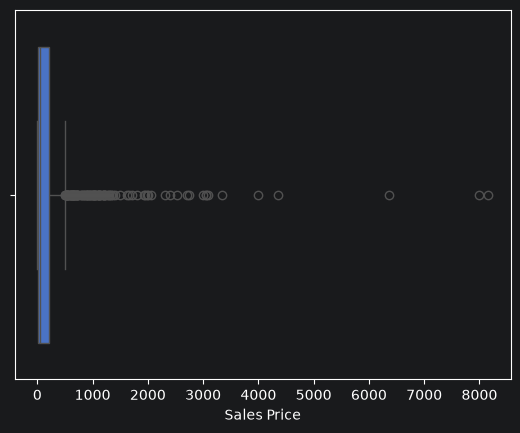

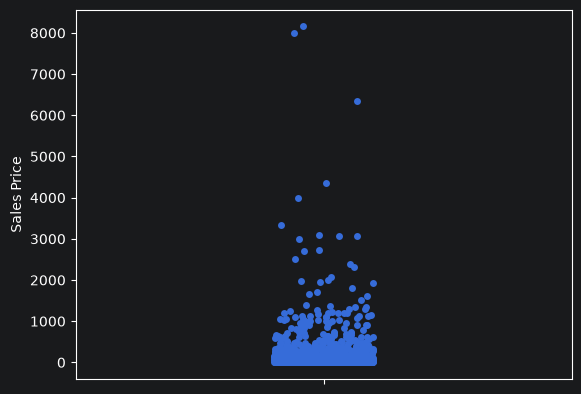

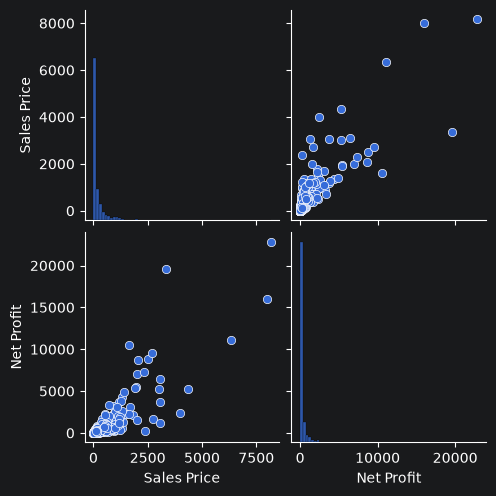

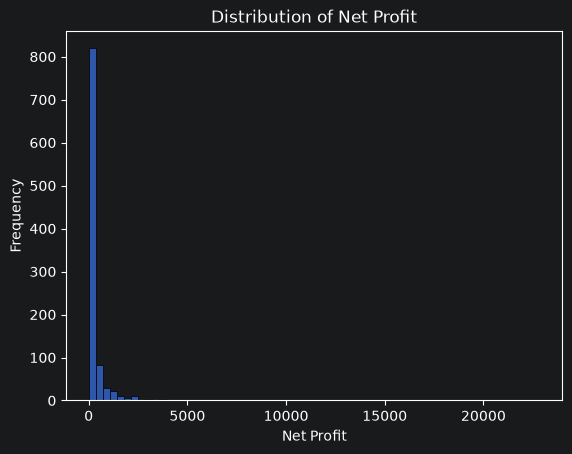

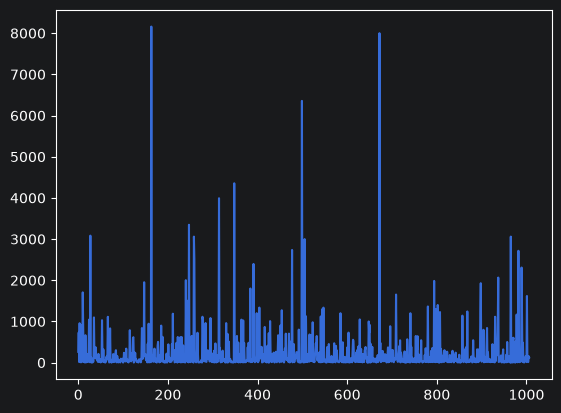

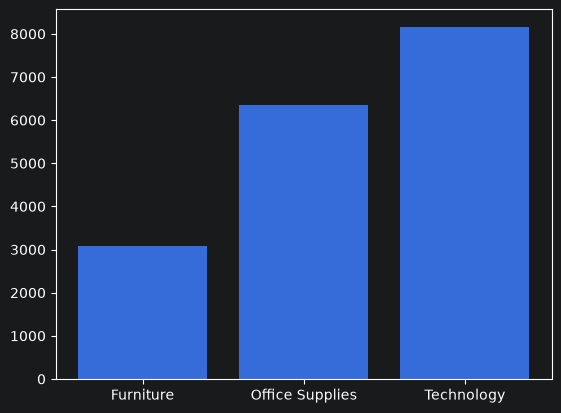

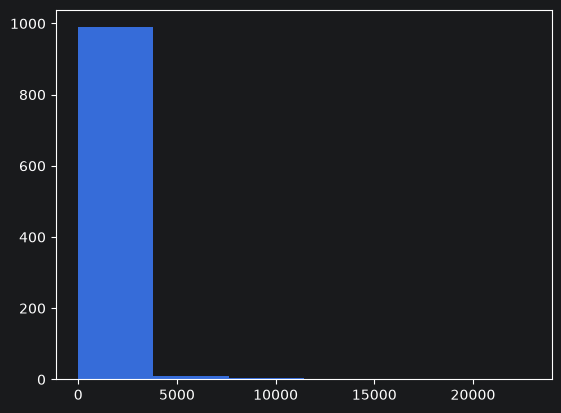

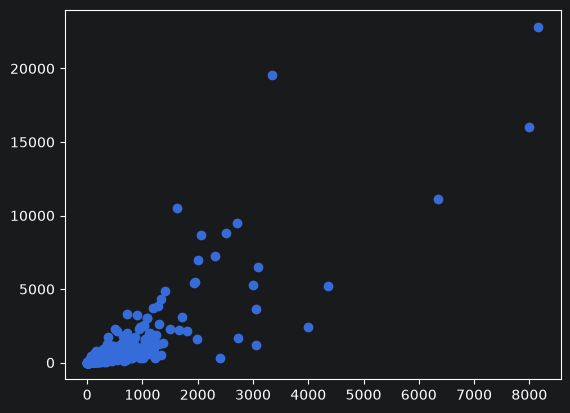

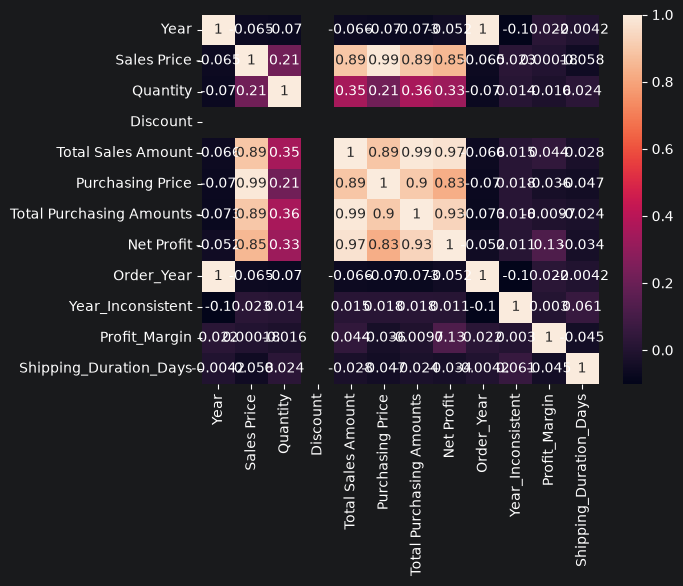

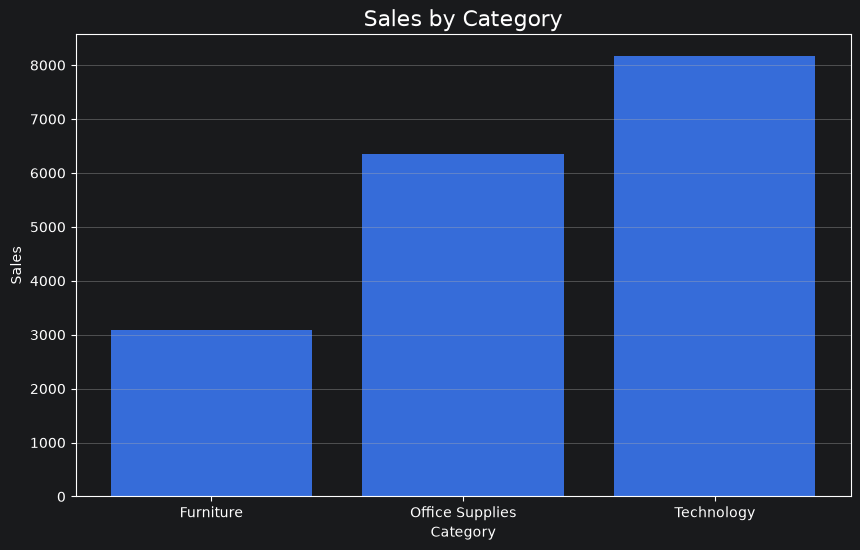

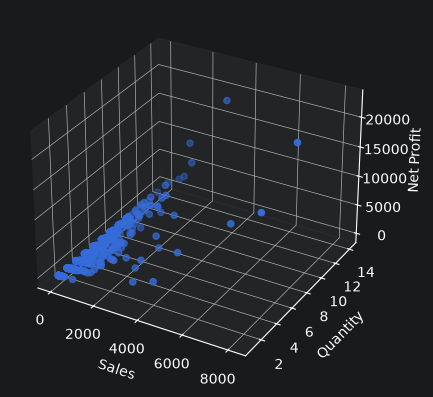

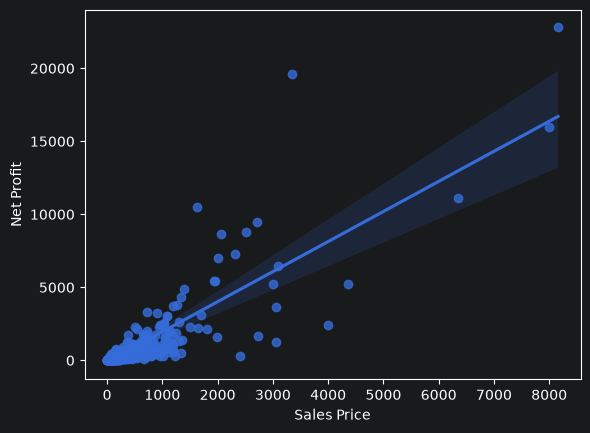

In [28]:
visual = Visualizations()

visual.plot1_sales_boxplot()
visual.plot2_sales_stripplot()
visual.plot3_sales_profit_pairplot()
visual.plot4_profit_distribution()
visual.plot5_sales_line()
visual.plot6_sales_by_category()
visual.plot7_profit_histogram()
visual.plot8_sales_profit_scatter()
visual.plot9_correlation_heatmap()
visual.plot10_sales_by_category_bar()
visual.plot11_3d_sales_quantity_profit()
visual.plot12_sales_profit_regression()

plt.show()

# 14. Export plots

In [29]:
visual.save_plots()

All plots exported successfully.


# 15. Export cleaned dataset

In [30]:
data.to_excel(
    r'C:\Users\eslam\Downloads\DEPI\Technical\plots & cleaned file\sales_data_cleaned.xlsx',
    index=False
)

print("Cleaned data exported successfully.")

Cleaned data exported successfully.


# 16. Final checks

In [31]:
print("Rows:", len(data))
print("Columns:", data.shape[1])
print("Duplicate rows:", data.duplicated().sum())
print("Total missing values:", data.isna().sum().sum())

Rows: 1007
Columns: 29
Duplicate rows: 0
Total missing values: 0


# End Of Project
## ~Eslam Mamdouh Awaga